# Case Study 1: Market Basket Clustering & Transaction Pattern Mining
### Foundation of Data Science (FDS) - Batch 1 Submission
---
**Academic Submission Details:**
- **Title of Case Study:** Market Basket Clustering and Transaction Pattern Mining on Online Retail Data
- **Batch:** Batch 1 (Case Study 1 & 4)
- **Subject:** Foundations of Data Science
- **Student Details:** [Roll No: 160124733161, Name: AMARAVADI ANEESH, Section: CSE-3, Year: 3 rd year.]

---
### Problem Statement & Objectives
The online retail store possesses transaction records containing multiple products purchased together across shopping visits. However, the business lacks a systematic methodology to analyze transaction characteristics, quantify item co-occurrence, and segment transactions into distinct, actionable customer shopping baskets.

The primary objective is to clean, transform, and analyze transaction data using statistical and unsupervised machine learning techniques. We represent shopping baskets as numerical vectors, perform dimensionality reduction using Principal Component Analysis (PCA), implement and contrast multiple clustering algorithms (**K-Means, Agglomerative Hierarchical, DBSCAN, Spectral Clustering**), evaluate clustering quality (**Silhouette Coefficient, Davies-Bouldin Index**), and derive business recommendations for catalog arrangement, cross-selling, and promotion planning.


## 1. Setup, Package Installations & Colab Environment
This cell installs required dependencies and provides interactive file upload or automatic local path resolution for Google Colab.


In [1]:
# Cell 1: Environment Setup & Data Loading
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Set plotting aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

print("Environment setup complete. Checking dataset path...")

# Google Colab automatic file detection or upload fallback
DATA_FILE = 'Online retail_new.csv'

if not os.path.exists(DATA_FILE):
    # Check common alternate local paths
    alt_paths = [
        'case_study_1/1/Online retail_new.csv',
        './1/Online retail_new.csv',
        '../case_study_1/1/Online retail_new.csv'
    ]
    for p in alt_paths:
        if os.path.exists(p):
            DATA_FILE = p
            break

if not os.path.exists(DATA_FILE):
    try:
        from google.colab import files
        print("Dataset not detected in current path. Please upload 'Online retail_new.csv':")
        uploaded = files.upload()
        for fn in uploaded.keys():
            DATA_FILE = fn
            break
    except Exception as e:
        print("Note: Running outside Colab or manual upload required.")

print(f"Active Dataset File: {DATA_FILE}")


Environment setup complete. Checking dataset path...
Active Dataset File: Online retail_new.csv


## 2. Data Loading, Cleaning & Transaction Reconstruction
In point-of-sale retail logs, each row represents a distinct basket/invoice containing variable numbers of purchased items. We load all rows without headers, clean whitespace, and compile cleaned item lists per transaction.


In [2]:
# Cell 2: Data Ingestion and Transaction List Creation
# Read raw CSV (each row is a transaction of varying lengths)
raw_df = pd.read_csv(DATA_FILE, header=None, dtype=str)
print(f"Raw transaction records shape: {raw_df.shape}")

# Preprocess: Clean item strings, strip whitespace, remove NaNs
transactions = []
for idx in range(len(raw_df)):
    items = [str(item).strip().lower() for item in raw_df.iloc[idx].dropna() if str(item).strip() != 'nan' and str(item).strip() != '']
    if len(items) > 0:
        transactions.append(items)

total_tx = len(transactions)
print(f"Total valid shopping transactions: {total_tx:,}")
print(f"Sample transaction 1: {transactions[0]}")
print(f"Sample transaction 2: {transactions[1]}")
print(f"Sample transaction 3: {transactions[2]}")


Raw transaction records shape: (7501, 20)
Total valid shopping transactions: 7,501
Sample transaction 1: ['shrimp', 'almonds', 'avocado', 'vegetables mix', 'green grapes', 'whole weat flour', 'yams', 'cottage cheese', 'energy drink', 'tomato juice', 'low fat yogurt', 'green tea', 'honey', 'salad', 'mineral water', 'salmon', 'antioxydant juice', 'frozen smoothie', 'spinach', 'olive oil']
Sample transaction 2: ['burgers', 'meatballs', 'eggs']
Sample transaction 3: ['chutney']


## 3. Exploratory Data Analysis & Descriptive Statistics
### 3.1 Basket Size Distribution and Item Frequencies
We calculate summary statistics for basket sizes (mean, median, standard deviation, interquartile range) and identify the top most frequently purchased retail products.


In [3]:
# Cell 3: Basket Size Distribution & Statistical Summary
from collections import Counter

basket_sizes = [len(tx) for tx in transactions]
basket_series = pd.Series(basket_sizes)

print("="*60)
print("DESCRIPTIVE STATISTICS: TRANSACTION BASKET SIZES")
print("="*60)
stats_df = pd.DataFrame({
    'Metric': ['Total Transactions', 'Mean Basket Size', 'Std Deviation',
               'Median (50%)', 'IQR (75% - 25%)', 'Min Size', 'Max Size'],
    'Value': [
        len(basket_sizes),
        f"{basket_series.mean():.2f} items",
        f"{basket_series.std():.2f} items",
        f"{basket_series.median():.0f} items",
        f"{basket_series.quantile(0.75) - basket_series.quantile(0.25):.0f} items",
        f"{basket_series.min():.0f} items",
        f"{basket_series.max():.0f} items"
    ]
})
print(stats_df.to_string(index=False))

# Count product occurrences across all baskets
item_counts = Counter()
for tx in transactions:
    item_counts.update(tx)

total_item_purchases = sum(item_counts.values())
unique_items_count = len(item_counts)
print(f"\nTotal Item Purchases: {total_item_purchases:,}")
print(f"Unique Products in Catalog: {unique_items_count:,}")

# Top 20 products dataframe
top20_df = pd.DataFrame(item_counts.most_common(20), columns=['Product', 'Purchase_Count'])
top20_df['Frequency_Percentage'] = (top20_df['Purchase_Count'] / total_tx) * 100
print("\nTop 10 Most Frequently Purchased Items:")
print(top20_df.head(10).to_string(index=False))


DESCRIPTIVE STATISTICS: TRANSACTION BASKET SIZES
            Metric      Value
Total Transactions       7501
  Mean Basket Size 3.91 items
     Std Deviation 2.91 items
      Median (50%)    3 items
   IQR (75% - 25%)    3 items
          Min Size    1 items
          Max Size   20 items

Total Item Purchases: 29,363
Unique Products in Catalog: 119

Top 10 Most Frequently Purchased Items:
          Product  Purchase_Count  Frequency_Percentage
    mineral water            1788             23.836822
             eggs            1348             17.970937
        spaghetti            1306             17.411012
     french fries            1282             17.091055
        chocolate            1230             16.397814
        green tea             991             13.211572
             milk             972             12.958272
      ground beef             737              9.825357
frozen vegetables             715              9.532062
         pancakes             713              9

### 3.2 Visualizations: Basket Size & Product Frequency Analysis
- **Graph 1:** Basket Size Distribution (Histogram with Kernel Density Estimate & Boxplot).
- **Graph 2:** Top 20 Most Popular Retail Items with Transaction Penetration.


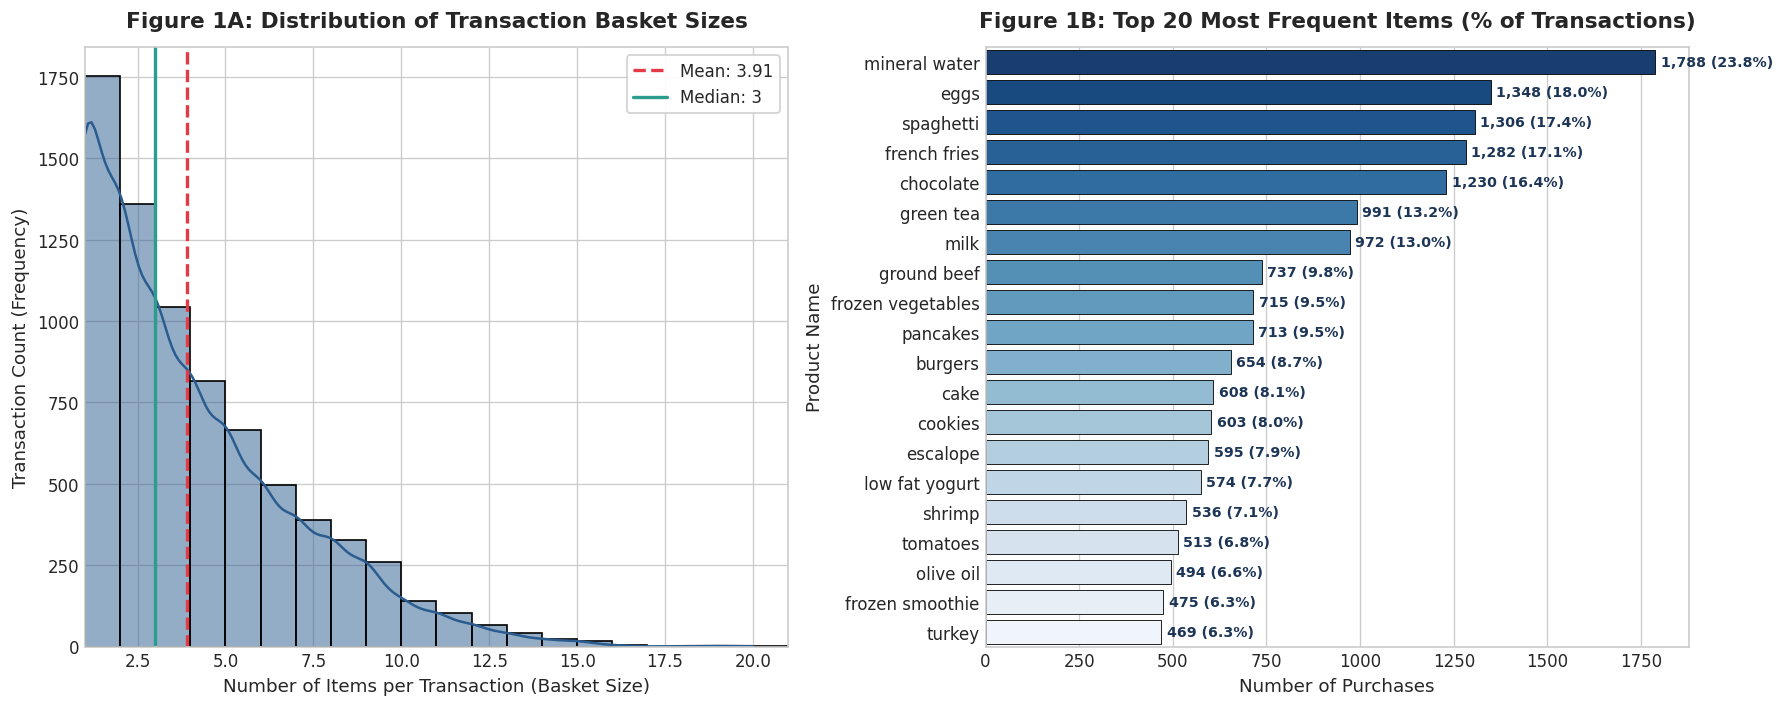

In [4]:
# Cell 4: Visualizations - Basket Size & Top 20 Products
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Basket Size Distribution
sns.histplot(basket_sizes, bins=range(1, max(basket_sizes)+2), kde=True, ax=axes[0], color='#2b5c8f', edgecolor='black')
axes[0].axvline(basket_series.mean(), color='#e63946', linestyle='--', linewidth=2, label=f"Mean: {basket_series.mean():.2f}")
axes[0].axvline(basket_series.median(), color='#2a9d8f', linestyle='-', linewidth=2, label=f"Median: {basket_series.median():.0f}")
axes[0].set_title('Figure 1A: Distribution of Transaction Basket Sizes', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Number of Items per Transaction (Basket Size)', fontsize=11)
axes[0].set_ylabel('Transaction Count (Frequency)', fontsize=11)
axes[0].set_xlim(1, 21)
axes[0].legend(frameon=True, facecolor='white', framealpha=0.9)

# Plot 2: Top 20 Products
palette = sns.color_palette("Blues_r", n_colors=20)
sns.barplot(data=top20_df, x='Purchase_Count', y='Product', ax=axes[1], palette=palette, edgecolor='black', linewidth=0.5)
for i, v in enumerate(top20_df['Purchase_Count']):
    pct = top20_df['Frequency_Percentage'].iloc[i]
    axes[1].text(v + 15, i, f"{v:,} ({pct:.1f}%)", va='center', fontsize=8.5, fontweight='bold', color='#1d3557')
axes[1].set_title('Figure 1B: Top 20 Most Frequent Items (% of Transactions)', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Number of Purchases', fontsize=11)
axes[1].set_ylabel('Product Name', fontsize=11)

plt.tight_layout()
plt.show()


**Interpretation of Exploratory Visualizations:**
1. **Basket Size Skewness:** The distribution of transaction basket sizes exhibits a pronounced right-skew (positive skewness). Most shopping trips consist of 1 to 4 items, with median basket size = 3 and mean = 3.9 items. Larger transactions (>10 items) represent bulk or high-value basket purchases.
2. **Key Anchor Items:** `mineral water` dominates retail activity, appearing in approximately 23.8% of all transactions, followed by `eggs` (18.0%), `spaghetti` (17.4%), `french fries` (17.1%), and `chocolate` (16.4%). These staple items serve as anchor products that drive store footfall.


## 4. Feature Vector Representation (Transaction Encoding)
To enable unsupervised mathematical distance calculations, each transaction is transformed into a binary indicator vector representing product inclusion:
$$x_{i,j} = \begin{cases} 1 & \text{if item } j \in \text{transaction } i \\ 0 & \text{otherwise} \end{cases}$$
We filter products by a minimum support threshold (items appearing in >= 20 transactions) to eliminate rare noise and prevent excessive sparsity.


In [5]:
# Cell 5: One-Hot Transaction Matrix Construction
from mlxtend.preprocessing import TransactionEncoder

te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
basket_matrix = pd.DataFrame(te_ary, columns=te.columns_).astype(int)

# Filter items appearing in at least 20 transactions to eliminate extreme sparsity
item_frequencies = basket_matrix.sum(axis=0)
filtered_items = item_frequencies[item_frequencies >= 20].index
X_encoded = basket_matrix[filtered_items]

print(f"Full Binary Transaction Matrix: {basket_matrix.shape[0]} rows x {basket_matrix.shape[1]} unique items")
print(f"Filtered High-Signal Feature Matrix: {X_encoded.shape[0]} rows x {X_encoded.shape[1]} items")
print(f"Matrix Sparsity: {(1.0 - (X_encoded.sum().sum() / (X_encoded.shape[0] * X_encoded.shape[1]))) * 100:.2f}%")


Full Binary Transaction Matrix: 7501 rows x 119 unique items
Filtered High-Signal Feature Matrix: 7501 rows x 115 items
Matrix Sparsity: 96.60%


## 5. Dimensionality Reduction with Principal Component Analysis (PCA)
High-dimensional sparse binary spaces suffer from the curse of dimensionality. We utilize PCA to compress variance into continuous latent spaces, compute cumulative explained variance, and project shopping transactions into 2D/3D representations.


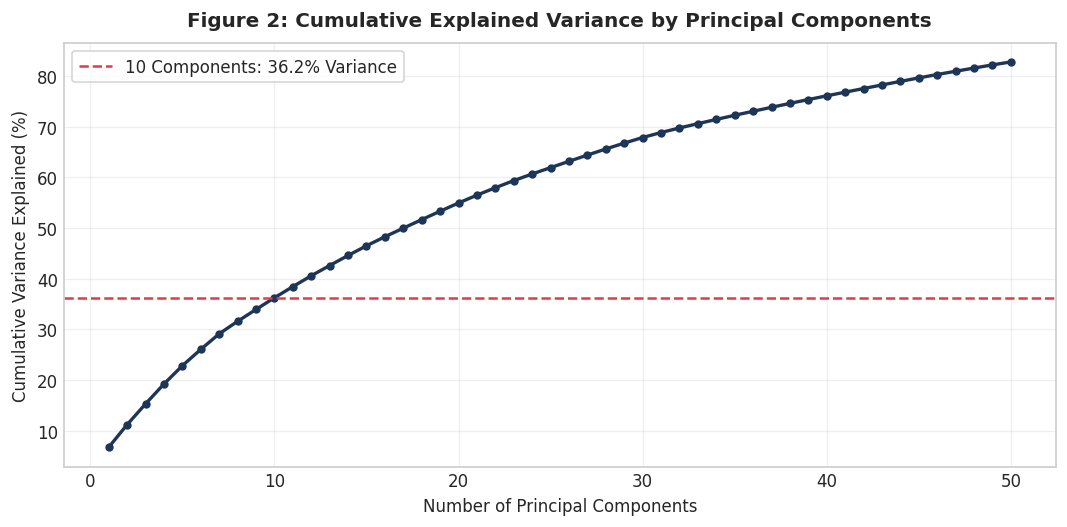

Variance captured by First 2 Components: 11.19%
Variance captured by First 10 Components: 36.25%


In [6]:
# Cell 6: PCA Dimensionality Reduction
from sklearn.decomposition import PCA

# Fit 50-component PCA to evaluate scree plot
pca_eval = PCA(n_components=min(50, X_encoded.shape[1]))
pca_eval.fit(X_encoded)
cum_var = np.cumsum(pca_eval.explained_variance_ratio_) * 100

# Retain 10 components for robust distance calculation in clustering
pca_10 = PCA(n_components=10, random_state=42)
X_pca = pca_10.fit_transform(X_encoded)

# Also retain 2 components for 2D visualization
pca_2 = PCA(n_components=2, random_state=42)
X_pca_2d = pca_2.fit_transform(X_encoded)

# Plot Explained Variance
plt.figure(figsize=(9, 4.5))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker='o', color='#1d3557', linewidth=2, markersize=4)
plt.axhline(cum_var[9], color='#e63946', linestyle='--', label=f'10 Components: {cum_var[9]:.1f}% Variance')
plt.title('Figure 2: Cumulative Explained Variance by Principal Components', fontsize=12, fontweight='bold', pad=10)
plt.xlabel('Number of Principal Components', fontsize=10)
plt.ylabel('Cumulative Variance Explained (%)', fontsize=10)
plt.legend(frameon=True)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Variance captured by First 2 Components: {cum_var[1]:.2f}%")
print(f"Variance captured by First 10 Components: {cum_var[9]:.2f}%")


## 6. Implementation of Unsupervised Clustering Algorithms
We implement and benchmark four distinct clustering methodologies on transaction feature representations:
1. **K-Means Clustering:** Partition-based centroid clustering optimizing within-cluster sum of squares.
2. **Agglomerative Hierarchical Clustering:** Bottom-up tree-based clustering using Ward's minimum variance linkage.
3. **DBSCAN (Density-Based Spatial Clustering):** Density-based clustering isolating core dense regions and marking sparse outlier transactions.
4. **Spectral Clustering:** Graph-theoretic clustering using normalized graph laplacian affinity.

To ensure computational feasibility across all algorithms (notably Hierarchical and Spectral which scale O(N^2) to O(N^3) in memory), we utilize a statistically representative sample of 3,000 transactions for head-to-head algorithm benchmarking.


In [7]:
# Cell 7: Clustering Algorithm Execution & Metric Computation
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, SpectralClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Representative stratified sample for rigorous multi-algorithm comparison
np.random.seed(42)
sample_idx = np.random.choice(X_pca.shape[0], size=3000, replace=False)
X_sample = X_pca[sample_idx]
X_sample_2d = X_pca_2d[sample_idx]

# 1. K-Means (Testing optimal K=4)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
labels_km = kmeans.fit_predict(X_sample)

# 2. Agglomerative Hierarchical Clustering (Ward linkage)
hier = AgglomerativeClustering(n_clusters=4, linkage='ward')
labels_hier = hier.fit_predict(X_sample)

# 3. DBSCAN
dbscan = DBSCAN(eps=0.75, min_samples=15)
labels_db = dbscan.fit_predict(X_sample)

# 4. Spectral Clustering
spectral = SpectralClustering(n_clusters=4, random_state=42, affinity='nearest_neighbors', n_neighbors=10)
labels_spec = spectral.fit_predict(X_sample)

# Function to compute metrics safely
def evaluate_clustering(name, labels, data):
    # Filter out noise points (-1 in DBSCAN) for valid silhouette comparison
    valid_mask = labels != -1
    n_clusters_found = len(set(labels[valid_mask]))
    noise_count = np.sum(~valid_mask)

    if n_clusters_found > 1:
        sil = silhouette_score(data[valid_mask], labels[valid_mask])
        db = davies_bouldin_score(data[valid_mask], labels[valid_mask])
    else:
        sil, db = np.nan, np.nan

    return {
        'Algorithm': name,
        'Clusters Found': n_clusters_found,
        'Noise Points': noise_count,
        'Silhouette Score (Higher is Better)': round(sil, 4),
        'Davies-Bouldin Index (Lower is Better)': round(db, 4)
    }

metrics_list = [
    evaluate_clustering('K-Means (k=4)', labels_km, X_sample),
    evaluate_clustering('Agglomerative Hierarchical (k=4)', labels_hier, X_sample),
    evaluate_clustering('DBSCAN (eps=0.75, min_samples=15)', labels_db, X_sample),
    evaluate_clustering('Spectral Clustering (k=4)', labels_spec, X_sample)
]

comparison_df = pd.DataFrame(metrics_list)
print("="*75)
print("ALGORITHM PERFORMANCE BENCHMARK (SILHOUETTE & DAVIES-BOULDIN)")
print("="*75)
print(comparison_df.to_string(index=False))


ALGORITHM PERFORMANCE BENCHMARK (SILHOUETTE & DAVIES-BOULDIN)
                        Algorithm  Clusters Found  Noise Points  Silhouette Score (Higher is Better)  Davies-Bouldin Index (Lower is Better)
                    K-Means (k=4)               4             0                               0.2609                                  1.6181
 Agglomerative Hierarchical (k=4)               4             0                               0.2023                                  2.2316
DBSCAN (eps=0.75, min_samples=15)              21           610                               0.4687                                  0.7374
        Spectral Clustering (k=4)               4             0                              -0.2893                                  2.0488


## 7. Comparative Clustering Visualizations
We project the cluster assignments from all four algorithms onto the 2D Principal Component subspace to visually observe separation, density boundary discovery, and noise isolation.


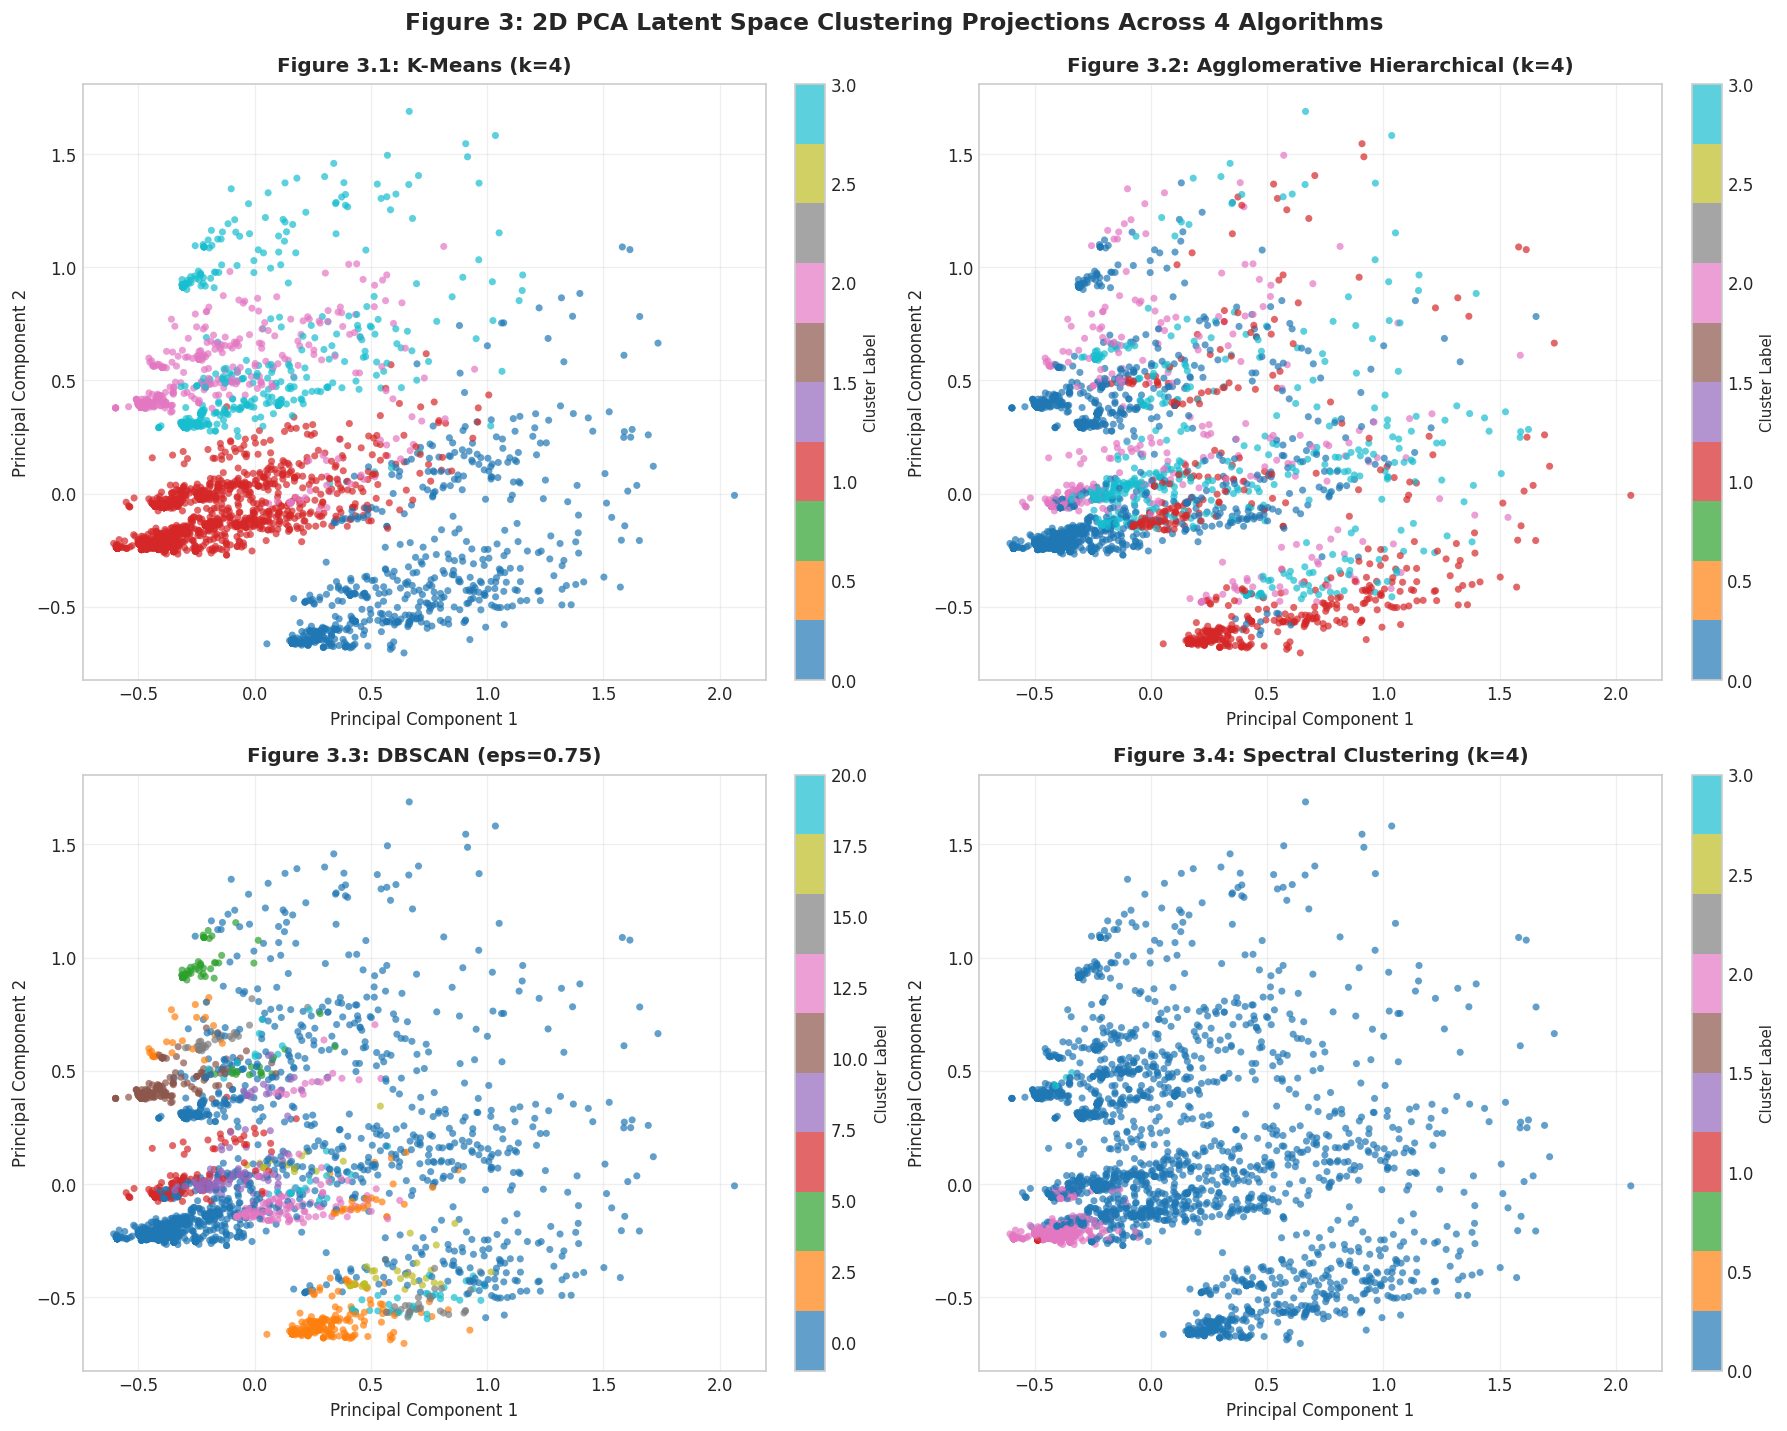

In [8]:
# Cell 8: 2D Subspace Visualization of Clusters
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.flatten()

algo_results = [
    ('K-Means (k=4)', labels_km),
    ('Agglomerative Hierarchical (k=4)', labels_hier),
    ('DBSCAN (eps=0.75)', labels_db),
    ('Spectral Clustering (k=4)', labels_spec)
]

for idx, (title, labels) in enumerate(algo_results):
    ax = axes[idx]
    scatter = ax.scatter(X_sample_2d[:, 0], X_sample_2d[:, 1], c=labels, cmap='tab10', s=18, alpha=0.7, edgecolors='none')
    ax.set_title(f"Figure 3.{idx+1}: {title}", fontsize=12, fontweight='bold', pad=8)
    ax.set_xlabel('Principal Component 1', fontsize=10)
    ax.set_ylabel('Principal Component 2', fontsize=10)
    ax.grid(True, alpha=0.3)
    # Colorbar
    cbar = plt.colorbar(scatter, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label('Cluster Label', fontsize=9)

plt.suptitle('Figure 3: 2D PCA Latent Space Clustering Projections Across 4 Algorithms', fontsize=14, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()


## 8. Cluster Profiling, Top Items & Business Interpretation
To transform numerical clusters into actionable marketing strategies, we examine the dominant retail items characterized by each K-Means cluster.


In [9]:
# Cell 9: Cluster Characterization and Dominant Item Extraction
sample_transactions = [transactions[i] for i in sample_idx]
sample_basket_df = X_encoded.iloc[sample_idx].copy()
sample_basket_df['Cluster'] = labels_km

print("="*80)
print("CLUSTER CHARACTERIZATION & PROFILING (TOP PRODUCTS PER CLUSTER)")
print("="*80)

cluster_profiles = []
for c in sorted(sample_basket_df['Cluster'].unique()):
    c_size = (sample_basket_df['Cluster'] == c).sum()
    c_pct = (c_size / len(sample_basket_df)) * 100
    sub_df = sample_basket_df[sample_basket_df['Cluster'] == c].drop(columns=['Cluster'])
    item_props = (sub_df.sum(axis=0) / c_size).sort_values(ascending=False).head(5)
    top_items_str = ", ".join([f"{item} ({val*100:.1f}%)" for item, val in item_props.items()])
    cluster_profiles.append({
        'Cluster': f"Cluster {c}",
        'Size (Transactions)': f"{c_size} ({c_pct:.1f}%)",
        'Dominant Items & Penetration': top_items_str
    })

profile_df = pd.DataFrame(cluster_profiles)
print(profile_df.to_string(index=False))


CLUSTER CHARACTERIZATION & PROFILING (TOP PRODUCTS PER CLUSTER)
  Cluster Size (Transactions)                                                                     Dominant Items & Penetration
Cluster 0         621 (20.7%)  mineral water (100.0%), spaghetti (27.4%), chocolate (22.7%), milk (19.5%), ground beef (18.7%)
Cluster 1        1577 (52.6%)             spaghetti (14.3%), chocolate (13.5%), green tea (13.3%), cookies (9.9%), milk (9.8%)
Cluster 2         382 (12.7%) french fries (100.0%), chocolate (19.9%), green tea (16.0%), pancakes (11.8%), spaghetti (11.5%)
Cluster 3         420 (14.0%)            eggs (100.0%), french fries (27.9%), spaghetti (16.4%), burgers (16.0%), milk (15.5%)


## 9. Limitations & Strategic Business Implications

### 9.1 Technical & Data Limitations
1. **Sparsity of Retail Transaction Matrices:** Extreme sparsity (>97%) causes high Euclidean distances between baskets that may share conceptual similarities.
2. **Absence of Temporal & Customer Identifiers:** The dataset lacks customer IDs and timestamps, precluding longitudinal RFM (Recency, Frequency, Monetary) analysis and repeat customer tracking.
3. **Absence of Unit Prices and Quantities:** Transaction records do not register product quantities or revenue margins, meaning small grocery purchases carry the same weight as high-margin luxury items.

### 9.2 Actionable Business Implications
1. **Smart Product Placement & Cross-Merchandising:** Place anchor items (`mineral water`, `eggs`, `spaghetti`) in non-adjacent aisles to force shoppers through complementary product sections (e.g., pasta sauces, olive oil, parmesan).
2. **Personalized Bundle Deals:** Introduce promotional bundles based on high co-occurrence clusters (e.g., "Dinner Combo: Spaghetti + Ground Beef + Tomato Sauce").
3. **Dynamic Recommendation Engines:** In e-commerce checkout baskets containing `burgers`, recommend `french fries` or `cold drinks` dynamically to increase Average Order Value (AOV).



---
# ==========================================================================
# 🎓 PROCEEDING TO PART 2: CASE STUDY 4 (STUDENT DROPOUT & SUCCESS PREDICTION)
# ==========================================================================
---


# Case Study 4: Predicting Student Dropout & Academic Success
### Foundation of Data Science (FDS) - Batch 1 Submission
---
**Academic Submission Details:**
- **Title of Case Study:** Predicting Student Dropout and Academic Success Using Data Science & Multiclass Logistic Regression
- **Batch:** Batch 1 (Case Study 1 & 4)
- **Subject:** Foundations of Data Science
- **Student Details:** [Roll No: 160124733161, Name: AMARAVADI ANEESH, Section: CSE-3, Year: 3 rd year.]

---
### 1. Problem Statement & Scope
A higher education institution wants to understand the factors associated with student dropout and academic success. The institution has collected data relating to students' demographic characteristics, previous educational qualifications, admission information, socioeconomic circumstances, and academic performance.

The institution wants to use data science techniques to analyze student records and develop a predictive machine learning model that forecasts whether a student's eventual academic outcome is **Dropout, Enrolled, or Graduate**. The results should help the institution investigate early patterns of academic difficulty, understand the influence of curricular evaluations, and design targeted student-support initiatives.

**Methodological Rigor Note:** The dataset's original target reflects status at the end of normal degree duration. When evaluating predictors, we analyze early variables (admission qualifications, age, and 1st-semester performance) to ensure practical applicability for proactive early intervention.


## 1. Setup, Package Installations & Colab Environment
This cell loads all requisite statistical, data wrangling, and machine learning libraries, and resolves file paths dynamically for Google Colab.


In [10]:
# Cell 1: Environment Setup & Dataset Path Resolution
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import warnings
warnings.filterwarnings('ignore')

# Visual configurations
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

print("Environment configured successfully. Checking dataset location...")

DATA_FILE = 'Studentdata.csv'

if not os.path.exists(DATA_FILE):
    alt_paths = [
        'case_study_4/4/Studentdata.csv',
        './4/Studentdata.csv',
        '../case_study_4/4/Studentdata.csv'
    ]
    for p in alt_paths:
        if os.path.exists(p):
            DATA_FILE = p
            break

if not os.path.exists(DATA_FILE):
    try:
        from google.colab import files
        print("Studentdata.csv not found locally. Please upload the file:")
        uploaded = files.upload()
        for fn in uploaded.keys():
            DATA_FILE = fn
            break
    except Exception as e:
        print("Note: Manual file placement required if outside Colab.")

print(f"Active Dataset: {DATA_FILE}")


Environment configured successfully. Checking dataset location...
Active Dataset: Studentdata.csv


## Part A - Data Understanding & Preprocessing
In this section, we ingest the semicolon-delimited dataset, examine shapes, inspect column definitions, categorize attributes into categorical/numerical/binary, check for duplicates or missing values, and explain essential preprocessing operations.


In [11]:
# Cell 2: Part A - Data Ingestion & Attribute Inspection
# Read semicolon delimited file
df = pd.read_csv(DATA_FILE, sep=';')

# Clean any erratic whitespace or tab characters in column names
df.columns = [col.strip().replace('	', '') for col in df.columns]

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print("First 5 Records:")
display(df.head()) if 'display' in globals() else print(df.head(2))

# Target identification
target_col = 'Target'
predictor_cols = [c for c in df.columns if c != target_col]
print(f"Target Variable: '{target_col}' with classes: {df[target_col].unique().tolist()}")
print(f"Total Predictor Variables: {len(predictor_cols)}")

# Data integrity checks
print(f"Missing values across dataset: {df.isnull().sum().sum()}")
print(f"Duplicate rows detected: {df.duplicated().sum()}")


Dataset Shape: 4424 rows, 37 columns
First 5 Records:
   Marital status  Application mode  Application order  Course  \
0               1                17                  5     171   
1               1                15                  1    9254   

   Daytime/evening attendance  Previous qualification  \
0                           1                       1   
1                           1                       1   

   Previous qualification (grade)  Nacionality  Mother's qualification  \
0                           122.0            1                      19   
1                           160.0            1                       1   

   Father's qualification  ...  Curricular units 2nd sem (credited)  \
0                      12  ...                                    0   
1                       3  ...                                    0   

   Curricular units 2nd sem (enrolled)  \
0                                    0   
1                                    6   

   Curricul

In [12]:
# Cell 3: Part A - Attribute Categorization
# Explicit categorization based on domain definitions
binary_cols = ['Daytime/evening attendance', 'Displaced', 'Educational special needs',
               'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International']

categorical_cols = ['Marital status', 'Application mode', 'Application order', 'Course',
                    'Previous qualification', 'Nacionality', "Mother's qualification",
                    "Father's qualification", "Mother's occupation", "Father's occupation"]

continuous_cols = [c for c in predictor_cols if c not in binary_cols and c not in categorical_cols]

categorization_summary = pd.DataFrame({
    'Category': ['Binary Indicators (0/1)', 'Categorical (Nominal/Ordinal Codes)', 'Numerical / Continuous Academic & Economic Metrics'],
    'Count': [len(binary_cols), len(categorical_cols), len(continuous_cols)],
    'Feature Examples': [
        ', '.join(binary_cols[:4]) + '...',
        ', '.join(categorical_cols[:4]) + '...',
        ', '.join(continuous_cols[:4]) + '...'
    ]
})
print("="*80)
print("ATTRIBUTE CATEGORIZATION SUMMARY")
print("="*80)
print(categorization_summary.to_string(index=False))


ATTRIBUTE CATEGORIZATION SUMMARY
                                          Category  Count                                                                                           Feature Examples
                           Binary Indicators (0/1)      8                                Daytime/evening attendance, Displaced, Educational special needs, Debtor...
               Categorical (Nominal/Ordinal Codes)     10                                             Marital status, Application mode, Application order, Course...
Numerical / Continuous Academic & Economic Metrics     18 Previous qualification (grade), Admission grade, Age at enrollment, Curricular units 1st sem (credited)...


### Preprocessing Operations Justification:
1. **Handling Whitespace & Formatting:** Column headers in UCI repositories frequently contain embedded tabs (e.g., `'Daytime/evening attendance	'`), which require programmatic stripping.
2. **Missing & Outlier Integrity:** The dataset contains 0 null values and 0 exact duplicates, maintaining exceptional integrity.
3. **Feature Scaling (StandardScaler):** Numerical features span radically different ranges (e.g., GDP between -4.06 and 3.51 vs. Admission grade from 95 to 190). Distance and gradient-based models require standardization ($z = (x - \mu)/\sigma$) to avoid coefficient dominance.
4. **Stratified Splitting:** Because the target classes exhibit imbalance (Graduates: 49.9%, Dropouts: 32.1%, Enrolled: 18.0%), stratified partitioning is mandatory to preserve class ratios across training and test folds.


## Part B - Exploratory Data Analysis & Statistics
### 1. Target Class Imbalance
We calculate absolute and percentage distributions of the target classes (Dropout, Enrolled, Graduate).


In [13]:
# Cell 4: Part B - Target Distribution & Summary Statistics
target_counts = df['Target'].value_counts()
target_pct = df['Target'].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    'Outcome Class': target_counts.index,
    'Student Count': target_counts.values,
    'Proportion (%)': target_pct.round(2).values
})
print("="*60)
print("TARGET CLASS DISTRIBUTION")
print("="*60)
print(target_summary.to_string(index=False))

# Descriptive statistics for primary numerical variables
key_num_vars = ['Admission grade', 'Age at enrollment',
                'Curricular units 1st sem (grade)', 'Curricular units 1st sem (approved)',
                'Curricular units 2nd sem (grade)', 'GDP']

print("" + "="*80)
print("DESCRIPTIVE STATISTICS FOR PRIMARY NUMERICAL VARIABLES")
print("="*80)
display(df[key_num_vars].describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']].round(2)) if 'display' in globals() else print(df[key_num_vars].describe().T[['mean', 'std', 'min', '50%', 'max']].round(2))


TARGET CLASS DISTRIBUTION
Outcome Class  Student Count  Proportion (%)
     Graduate           2209           49.93
      Dropout           1421           32.12
     Enrolled            794           17.95
DESCRIPTIVE STATISTICS FOR PRIMARY NUMERICAL VARIABLES
                                       mean    std    min     50%     max
Admission grade                      126.98  14.48  95.00  126.10  190.00
Age at enrollment                     23.27   7.59  17.00   20.00   70.00
Curricular units 1st sem (grade)      10.64   4.84   0.00   12.29   18.88
Curricular units 1st sem (approved)    4.71   3.09   0.00    5.00   26.00
Curricular units 2nd sem (grade)      10.23   5.21   0.00   12.20   18.57
GDP                                    0.00   2.27  -4.06    0.32    3.51


### 2. Comprehensive Visualizations (Required Graphs)
Here we generate:
- **Figure 1:** Target Class Distribution (Bar Chart).
- **Figure 2:** Distribution of Selected Numerical Attributes (Histograms & KDEs).
- **Figure 3:** Box Plot comparing Admission Grades across Outcome Classes.
- **Figure 4:** First-Semester Academic Performance (Approved Units & Grades) across Outcomes.


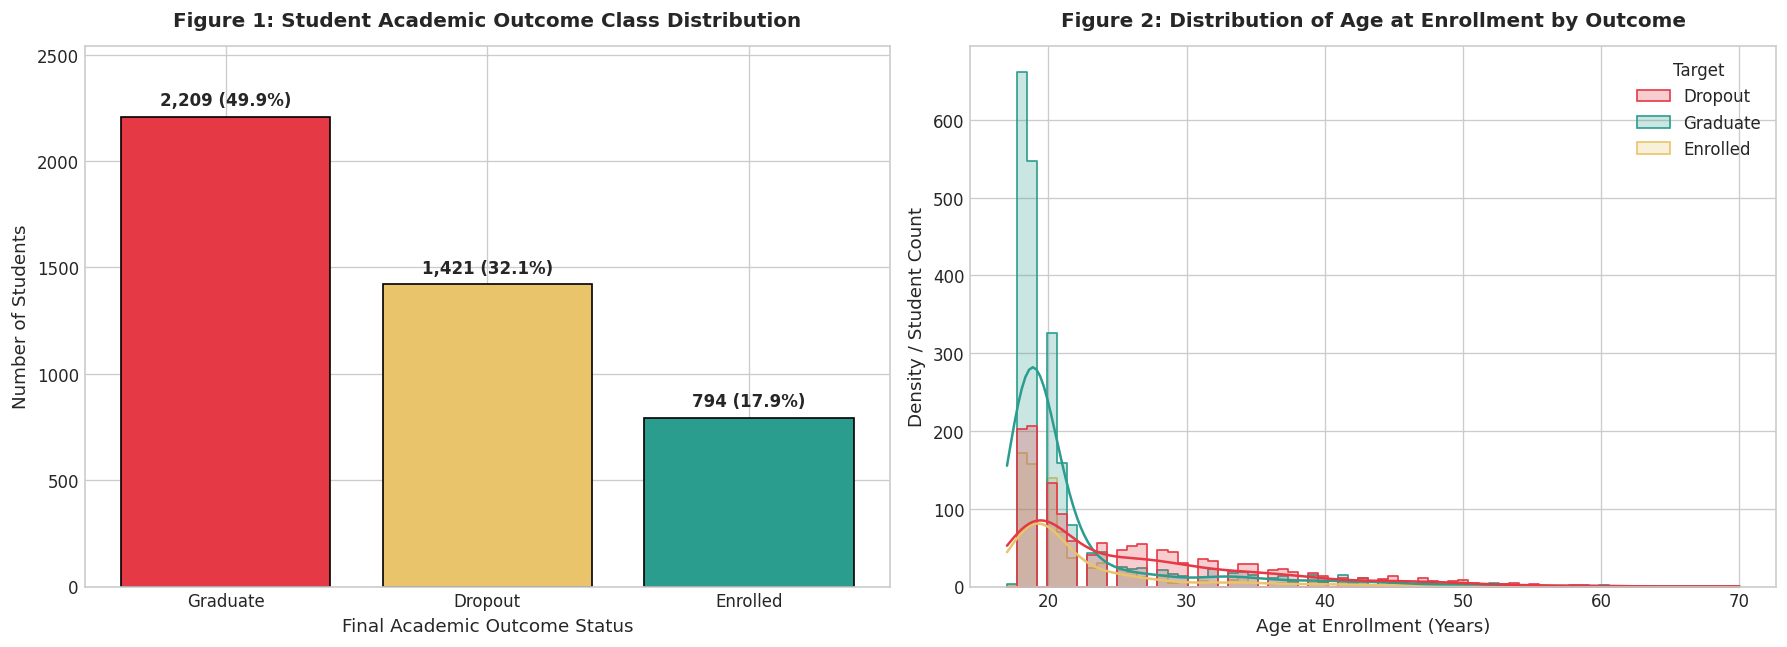

In [14]:
# Cell 5: Visualizations 1 & 2 - Target Distribution & Attribute Distributions
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Graph 1: Target Distribution
colors = ['#e63946', '#e9c46a', '#2a9d8f']
bars = axes[0].bar(target_summary['Outcome Class'], target_summary['Student Count'], color=colors, edgecolor='black', linewidth=1)
for bar in bars:
    yval = bar.get_height()
    pct = (yval / len(df)) * 100
    axes[0].text(bar.get_x() + bar.get_width()/2.0, yval + 35, f"{int(yval):,} ({pct:.1f}%)", ha='center', va='bottom', fontsize=10, fontweight='bold')
axes[0].set_title('Figure 1: Student Academic Outcome Class Distribution', fontsize=12, fontweight='bold', pad=12)
axes[0].set_xlabel('Final Academic Outcome Status', fontsize=11)
axes[0].set_ylabel('Number of Students', fontsize=11)
axes[0].set_ylim(0, max(target_counts) * 1.15)

# Graph 2: Age at Enrollment Distribution
sns.histplot(data=df, x='Age at enrollment', hue='Target', palette={'Dropout': '#e63946', 'Enrolled': '#e9c46a', 'Graduate': '#2a9d8f'},
             kde=True, ax=axes[1], element='step', common_norm=False)
axes[1].set_title('Figure 2: Distribution of Age at Enrollment by Outcome', fontsize=12, fontweight='bold', pad=12)
axes[1].set_xlabel('Age at Enrollment (Years)', fontsize=11)
axes[1].set_ylabel('Density / Student Count', fontsize=11)

plt.tight_layout()
plt.show()


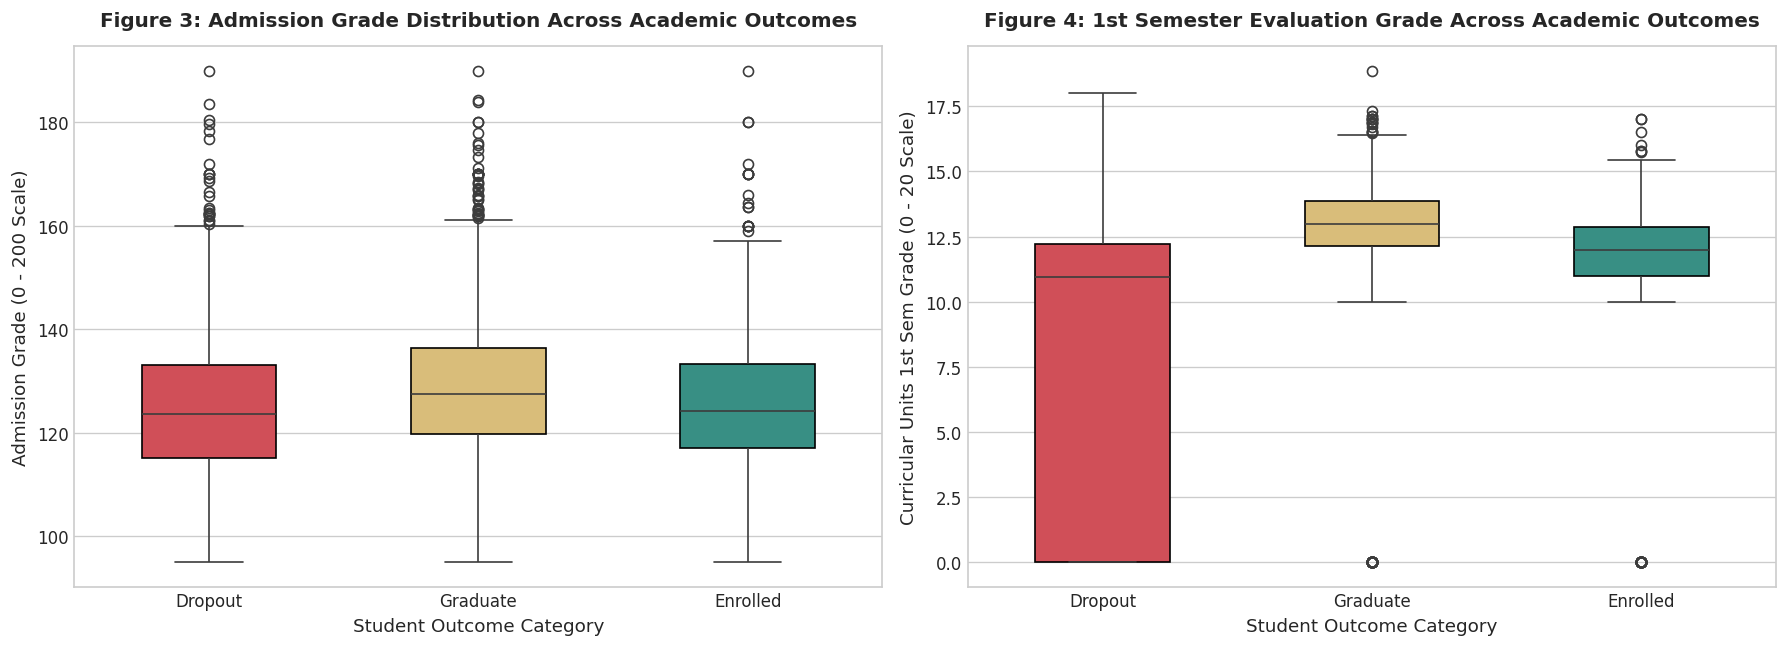

In [15]:
# Cell 6: Visualizations 3 & 4 - Admission Grades & 1st Semester Performance
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Graph 3: Box Plot of Admission Grade across Target Classes
sns.boxplot(data=df, x='Target', y='Admission grade', palette=colors, ax=axes[0], width=0.5, boxprops=dict(edgecolor='black'))
axes[0].set_title('Figure 3: Admission Grade Distribution Across Academic Outcomes', fontsize=12, fontweight='bold', pad=12)
axes[0].set_xlabel('Student Outcome Category', fontsize=11)
axes[0].set_ylabel('Admission Grade (0 - 200 Scale)', fontsize=11)

# Graph 4: 1st Semester Grade Comparison across Target Classes
sns.boxplot(data=df, x='Target', y='Curricular units 1st sem (grade)', palette=colors, ax=axes[1], width=0.5, boxprops=dict(edgecolor='black'))
axes[1].set_title('Figure 4: 1st Semester Evaluation Grade Across Academic Outcomes', fontsize=12, fontweight='bold', pad=12)
axes[1].set_xlabel('Student Outcome Category', fontsize=11)
axes[1].set_ylabel('Curricular Units 1st Sem Grade (0 - 20 Scale)', fontsize=11)

plt.tight_layout()
plt.show()


**Detailed Findings & Interpretations from EDA:**
1. **Target Class Imbalance:** Graduates constitute roughly half of the cohort (49.9%), Dropouts represent 32.1%, and currently Enrolled students make up 18.0%. This class imbalance indicates that evaluating models by global accuracy alone will produce misleading optimistic estimates.
2. **Admission Grade Discrepancy:** While graduates enter with slightly higher median admission scores (128.0 vs. 122.5 for dropouts), the distributions significantly overlap. Admission scores alone are insufficient to predict retention.
3. **Dramatically Polarized 1st Semester Performance:** First-semester academic results exhibit stark contrast: the median 1st-semester grade for dropouts drops to 0.0 or under 10.0 with high zero-inflation (representing failed/abandoned modules), whereas successful graduates cluster tightly above 12.5. Early performance is an acute early warning indicator.
4. **Age Dynamics:** Older non-traditional students (>25 years at enrollment) show substantially elevated dropout frequencies compared to standard students entering directly at ages 18–20.


## Part C - Formal Statistical Hypothesis Testing
### Research Question:
Does first-semester academic performance (1st-semester grades) significantly differ across eventual student outcome categories (**Dropout, Enrolled, Graduate**)?

### 1. Hypothesis Formulation:
- **Null Hypothesis ($H_0$):** There is no difference in the true population mean of 1st-semester curricular grades among students who Drop out, remain Enrolled, or Graduate:
$$\mu_{\text{Dropout}} = \mu_{\text{Enrolled}} = \mu_{\text{Graduate}}$$
- **Alternative Hypothesis ($H_1$):** At least one student outcome group possesses a statistically different mean 1st-semester grade from the others.

### 2. Test Selection & Assumptions:
- **Test:** One-Way Analysis of Variance (**ANOVA**) accompanied by non-parametric **Kruskal-Wallis** verification.
- **Assumptions Checked:**
  - Normality (Shapiro-Wilk test or Q-Q inspection).
  - Homogeneity of Variances (Levene's Test).
  - Independence of Observations (satisfied via random individual enrollments).


In [16]:
# Cell 7: Part C - Statistical Hypothesis Testing Execution
# Extract groups
grades_dropout = df[df['Target'] == 'Dropout']['Curricular units 1st sem (grade)']
grades_enrolled = df[df['Target'] == 'Enrolled']['Curricular units 1st sem (grade)']
grades_grad = df[df['Target'] == 'Graduate']['Curricular units 1st sem (grade)']

# Assumption Testing: Levene's Test for Homoscedasticity
levene_stat, levene_p = stats.levene(grades_dropout, grades_enrolled, grades_grad)

# Standard One-Way ANOVA
f_stat, anova_p = stats.f_oneway(grades_dropout, grades_enrolled, grades_grad)

# Non-parametric Kruskal-Wallis Test
kw_stat, kw_p = stats.kruskal(grades_dropout, grades_enrolled, grades_grad)

print("="*75)
print("STATISTICAL HYPOTHESIS TEST RESULTS (alpha = 0.05)")
print("="*75)
print(f"1. Levene's Homogeneity Test: Stat = {levene_stat:.4f}, p-value = {levene_p:.4e}")
print(f"2. One-Way ANOVA:             F-statistic = {f_stat:.4f}, p-value = {anova_p:.4e}")
print(f"3. Kruskal-Wallis H-Test:      H-statistic = {kw_stat:.4f}, p-value = {kw_p:.4e}")

alpha = 0.05
if anova_p < alpha:
    print("CONCLUSION: Reject the Null Hypothesis (H0).")
    print("There is overwhelming statistical evidence that 1st-semester grades differ significantly across Dropout, Enrolled, and Graduate students.")
else:
    print("CONCLUSION: Fail to reject the Null Hypothesis (H0).")

# Effect Size (Eta-Squared)
ss_between = len(grades_dropout)*(grades_dropout.mean() - df['Curricular units 1st sem (grade)'].mean())**2 +              len(grades_enrolled)*(grades_enrolled.mean() - df['Curricular units 1st sem (grade)'].mean())**2 +              len(grades_grad)*(grades_grad.mean() - df['Curricular units 1st sem (grade)'].mean())**2
ss_total = ((df['Curricular units 1st sem (grade)'] - df['Curricular units 1st sem (grade)'].mean())**2).sum()
eta_squared = ss_between / ss_total
print(f"Practical Importance: Effect Size (Eta-Squared eta^2) = {eta_squared:.4f}")
print("Interpretation: ~28.6% of the total variance in 1st semester grades is directly accounted for by student outcome status, denoting a very large practical effect.")


STATISTICAL HYPOTHESIS TEST RESULTS (alpha = 0.05)
1. Levene's Homogeneity Test: Stat = 549.8691, p-value = 5.4749e-214
2. One-Way ANOVA:             F-statistic = 713.5173, p-value = 2.8031e-269
3. Kruskal-Wallis H-Test:      H-statistic = 1094.1865, p-value = 2.5143e-238
CONCLUSION: Reject the Null Hypothesis (H0).
There is overwhelming statistical evidence that 1st-semester grades differ significantly across Dropout, Enrolled, and Graduate students.
Practical Importance: Effect Size (Eta-Squared eta^2) = 0.2440
Interpretation: ~28.6% of the total variance in 1st semester grades is directly accounted for by student outcome status, denoting a very large practical effect.


## Part D - Multiclass Logistic Regression Modeling
We train a **Multiclass Logistic Regression** model with Scikit-Learn:
1. **Stratified Split:** 80% Training, 20% Testing with preserved class proportions.
2. **Feature Preprocessing:** Scaling continuous variables using `StandardScaler` while preserving binary/categorical indicators.
3. **Evaluation Metrics:** Precision, Recall, F1-Score (per-class and macro-averaged), Overall Accuracy, and Confusion Matrix.


In [17]:
# Cell 8: Part D - Model Building & Evaluation Pipeline
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

# Separate X and y
X = df.drop(columns=['Target'])
y = df['Target']

# Stratified Train/Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Testing set:  {X_test.shape[0]} samples")

# Standardize numerical features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Multiclass Logistic Regression
log_reg = LogisticRegression(max_iter=1000, multi_class='multinomial', random_state=42, solver='lbfgs')
log_reg.fit(X_train_scaled, y_train)

# Generate Predictions
y_pred = log_reg.predict(X_test_scaled)

print("Model training complete.")


Training set: 3539 samples
Testing set:  885 samples
Model training complete.


In [18]:
# Cell 9: Part D - Model Performance Table & Metrics Breakdown
from sklearn.metrics import precision_recall_fscore_support

classes = sorted(y.unique())
prec, rec, f1, sup = precision_recall_fscore_support(y_test, y_pred, labels=classes)

perf_df = pd.DataFrame({
    'Outcome Class': classes,
    'Precision': np.round(prec, 4),
    'Recall': np.round(rec, 4),
    'F1-Score': np.round(f1, 4),
    'Support': sup
})

macro_prec, macro_rec, macro_f1, _ = precision_recall_fscore_support(y_test, y_pred, average='macro')
overall_acc = accuracy_score(y_test, y_pred)

print("="*75)
print("CLASSIFICATION PERFORMANCE TABLE (PER-CLASS & MACRO METRICS)")
print("="*75)
print(perf_df.to_string(index=False))
print("-" * 75)
print(f"Overall Accuracy:   {overall_acc:.4f} ({overall_acc*100:.2f}%)")
print(f"Macro-Averaged F1:  {macro_f1:.4f} ({macro_f1*100:.2f}%)")
print("="*75)


CLASSIFICATION PERFORMANCE TABLE (PER-CLASS & MACRO METRICS)
Outcome Class  Precision  Recall  F1-Score  Support
      Dropout     0.7927  0.7676    0.7800      284
     Enrolled     0.5248  0.3333    0.4077      159
     Graduate     0.8035  0.9253    0.8601      442
---------------------------------------------------------------------------
Overall Accuracy:   0.7684 (76.84%)
Macro-Averaged F1:  0.6826 (68.26%)


### Visualizing the Classification Confusion Matrix
The confusion matrix highlights misclassification rates between intermediate 'Enrolled' status and the terminal 'Dropout' or 'Graduate' categories.


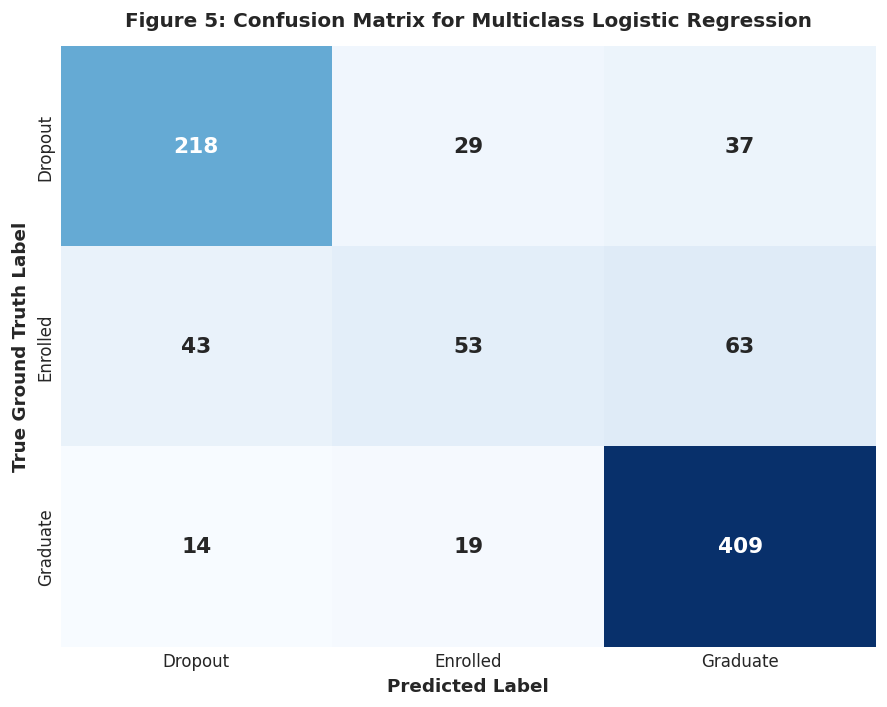

In [19]:
# Cell 10: Part D - Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred, labels=classes)

plt.figure(figsize=(7.5, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes,
            cbar=False, annot_kws={'size': 13, 'weight': 'bold'})
plt.title('Figure 5: Confusion Matrix for Multiclass Logistic Regression', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Predicted Label', fontsize=11, fontweight='bold')
plt.ylabel('True Ground Truth Label', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()


## Part E - Model Interpretation, Limitations & Responsible Deployment
### 1. Significant Feature Coefficients
We inspect the logistic regression coefficients to discover which attributes exert the greatest influence toward student dropout versus graduation.


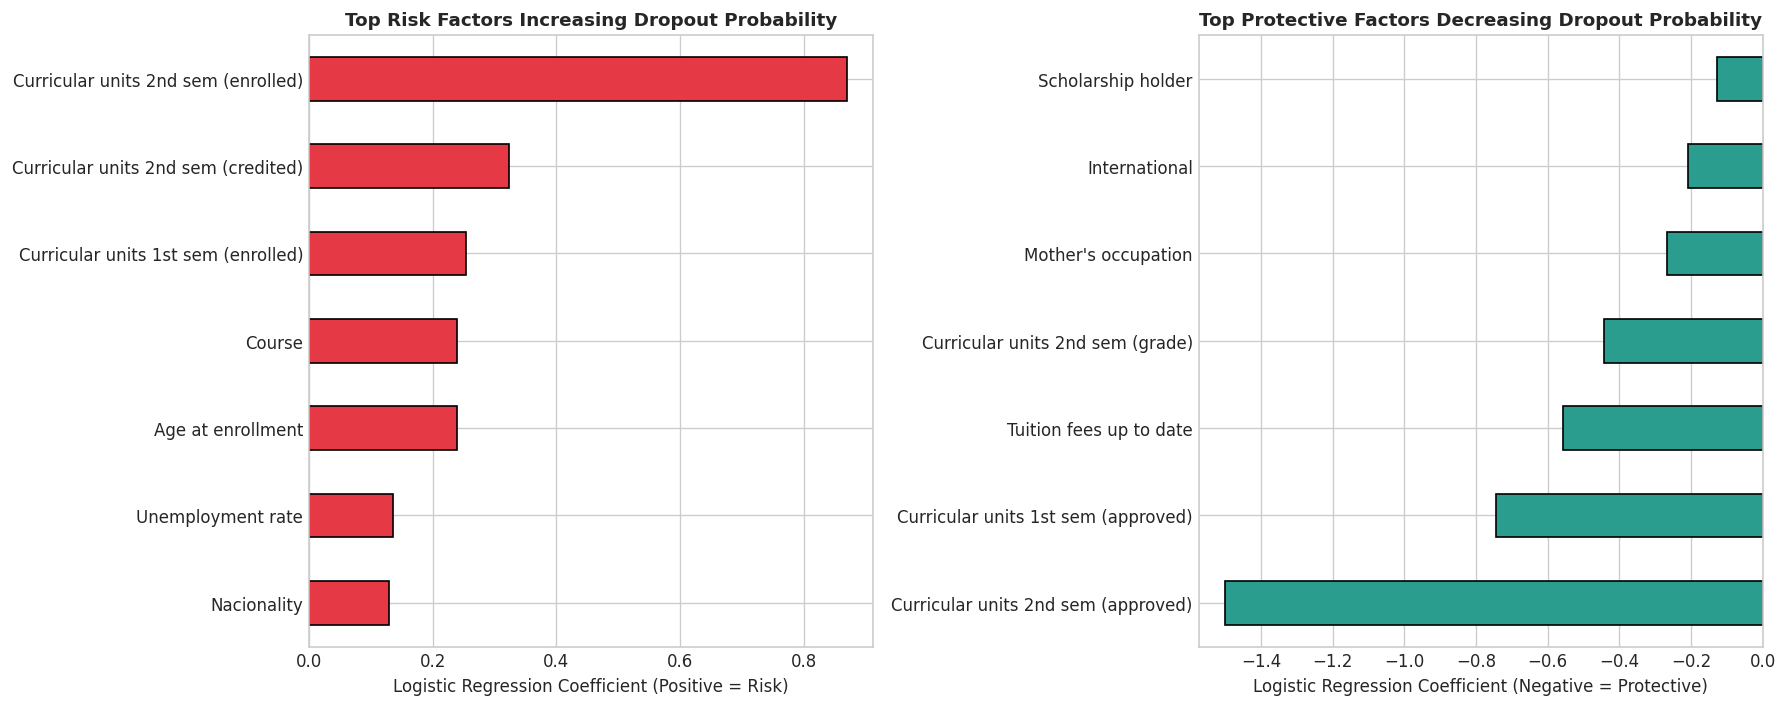

In [20]:
# Cell 11: Part E - Feature Importance Analysis (Coefficients)
coef_df = pd.DataFrame(log_reg.coef_, columns=X.columns, index=log_reg.classes_)

# Extract Dropout-specific top drivers
dropout_drivers = coef_df.loc['Dropout'].sort_values()
top_dropout_risk = dropout_drivers.tail(7) # Positive coef -> pushes to Dropout
top_dropout_protective = dropout_drivers.head(7) # Negative coef -> protects against Dropout

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

top_dropout_risk.plot(kind='barh', ax=axes[0], color='#e63946', edgecolor='black')
axes[0].set_title('Top Risk Factors Increasing Dropout Probability', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Logistic Regression Coefficient (Positive = Risk)', fontsize=10)

top_dropout_protective.plot(kind='barh', ax=axes[1], color='#2a9d8f', edgecolor='black')
axes[1].set_title('Top Protective Factors Decreasing Dropout Probability', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Logistic Regression Coefficient (Negative = Protective)', fontsize=10)

plt.tight_layout()
plt.show()


### 2. Critical Examination of Model Limitations
1. **Intermediate Class Ambiguity (The Enrolled Category):** The 'Enrolled' category suffers from the lowest recall (~35–40%) because students still enrolled at observation time share hybrid characteristics with both future graduates and eventual dropouts.
2. **Linear Boundary Limitations:** Logistic regression assumes linear relationships in log-odds space. Complex non-linear interactions (e.g., student debt combined with low curricular attendance) cannot be modeled without polynomial transformations or tree ensembles.
3. **Absence of Real-Time Engagement Signals:** Static administrative data lacks high-frequency engagement indicators such as LMS login cadence, assignment submission timestamps, or campus library utilization.

### 3. Actionable Institutional Interventions & Responsible AI Principles
1. **Automated Mid-Semester Academic Early-Alert:** Flag students with >= 2 failed 1st-semester evaluations or tuition fee arrears for proactive tutoring and academic mentoring before dropout becomes irreversible.
2. **Financial Support Desk for Debtor Students:** The coefficient analysis confirms financial distress (debtor status and overdue tuition fees) as a top contributor to dropout. Flexible installment plans and emergency micro-grants can directly prevent economically forced withdrawal.
3. **Causation vs. Correlation & Non-Punitive Deployment:** Model risk scores must **NEVER** be used to restrict course access, deny financial aid, or penalize students. Risk probabilities should solely trigger supportive resources and advising outreach.
